In [6]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from mpl_toolkits.mplot3d import Axes3D
import os
import matplotlib.pyplot as plt
import time



#Mes imports

fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

In [7]:
os.chdir(r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Sapphire\AR_estimation\Permittivity_study\index_data')
data = np.loadtxt('bulk_jhonson_christy_1972.txt')
#data = np.loadtxt('thin_Yakubovsky_2017_25nm.txt')


Lda = data[:,0]*1e-6

Au_n = data[:,1]
Au_k = data[:,2]


n = sc.interpolate.interp1d(Lda, Au_n, kind='cubic', bounds_error=False, fill_value=1)
k = sc.interpolate.interp1d(Lda, Au_k, kind='cubic', bounds_error=False, fill_value=0)

Lambda = np.linspace(400e-9, 1000e-9, 1000)

Text(0.5, 1.0, 'Index for gold')

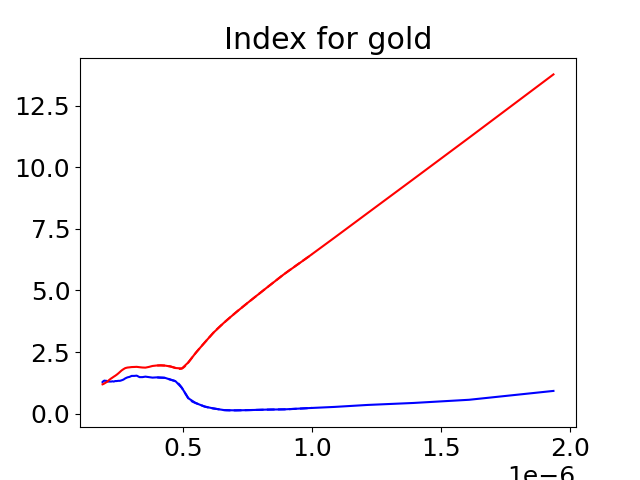

In [8]:
fig = plt.figure()

plt.plot(Lda, Au_n, color='b', label = 'n')
plt.plot(Lda, Au_k, color='r', label = 'k')

plt.plot(Lambda, n(Lambda), color='b', linestyle = '--')
plt.plot(Lambda, k(Lambda), color='r', linestyle = '--')

plt.title('Index for gold')

## Calculation for a sphere

In [9]:
r = 43e-9/2 #radius

eps1 = n(Lambda)**2 - k(Lambda)**2 
eps2 =  2*1j*n(Lambda)*k(Lambda)
eps = eps1 + eps2 # I Use the definition with a plane wave convention exp(jkz - jwt), cf PHD book Romain
eps_ext = 1*np.ones(np.size(Lambda))


# Calculate polarisability
   
V = np.pi*4/3*r**3
L = 1/3

A = V/L
B = eps - eps_ext
C = eps + ((1-L)/L)*eps_ext
alpha = A*B/C #The polarisability


#Calculate extinction cross sections

wavenumber = 2*np.pi*np.sqrt(eps_ext)/Lambda

sigma_abs = wavenumber*np.imag(alpha)

sigma_scat = wavenumber**4 / (6*np.pi) * np.abs(alpha)**2

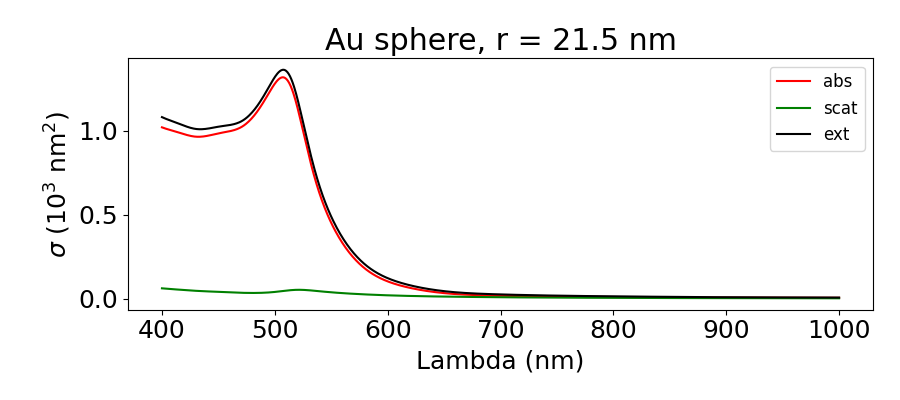

In [10]:
fig, ax = plt.subplots(figsize = (9,4))

ax.plot(Lambda*1e9, sigma_abs*1e15, color='red', label='abs')

ax.plot(Lambda*1e9, sigma_scat*1e15, color='green', label='scat')

ax.plot(Lambda*1e9, (sigma_abs+sigma_scat)*1e15, color='black', label='ext')


ax.set_xlabel('Lambda (nm)')

ax.set_ylabel(r'$\sigma$ ($10^3$ nm$^2$)')
plt.legend(fontsize=12)

plt.title('Au sphere, r = {:.1f} nm'.format(r*1e9))
plt.tight_layout()